### ⭐ Exercise 1 — "How Many Friends Do You Need?" 🤝
Copy the "wisdom of the crowd" simulation from Section 1. Try individual accuracies of
`p = [0.51, 0.60, 0.70, 0.80, 0.90]` and find how many models you need in each case to
reach 95% group accuracy. Plot all 5 curves on one graph. What's the pattern — does a
slightly better individual model make a big difference?

Answer:
        Observation:
          
          - As the number of models increases, group accuracy generally
            improves through majority voting.
          - When individual accuracy is 0.51, the group does not reach 95%
            accuracy within the tested range of 1 to 199 models.
          - Higher individual accuracy requires fewer models to reach the 95%
            target.
          - For example, accuracy of 0.60 requires 65 models, while 0.90
            requires only 3 models.

        Final Conclusion:

          Wisdom of the Crowd shows that combining multiple models through majority voting can improve overall accuracy. The individual model's accuracy plays an important role. Better individual models generally require fewer members to achieve high group accuracy.

Individual accuracy: 0.51 Models needed for 95% group accuracy: None
Individual accuracy: 0.6 Models needed for 95% group accuracy: 67
Individual accuracy: 0.7 Models needed for 95% group accuracy: 15
Individual accuracy: 0.8 Models needed for 95% group accuracy: 7
Individual accuracy: 0.9 Models needed for 95% group accuracy: 3


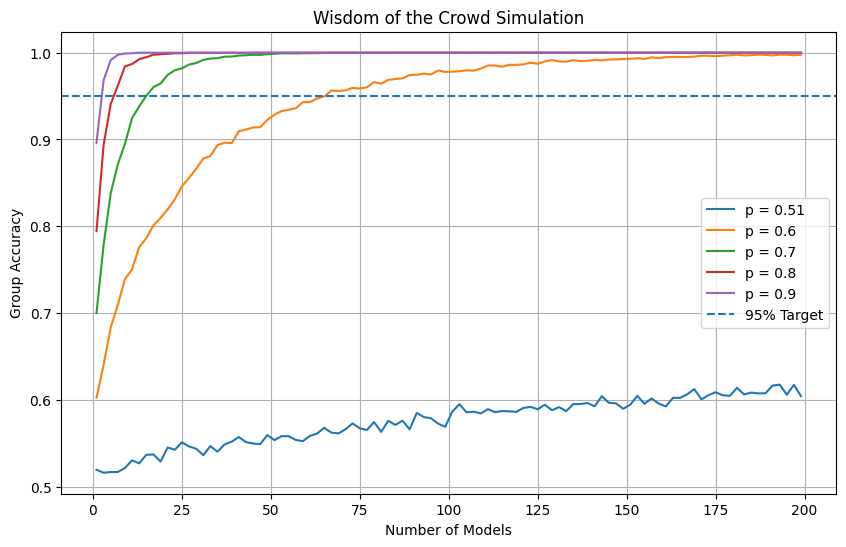

In [12]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)

# Function: Wisdom of Crowd Simulation
def simulate_group_accuracy(p, n_models, n_simulations=10000):

    correct_predictions = 0

    for _ in range(n_simulations):

        # Each model's prediction is either correct or incorrect.
        predictions = np.random.rand(n_models) < p

        # Majority voting
        if np.sum(predictions) > n_models / 2:
            correct_predictions += 1

    return correct_predictions / n_simulations



# Individual model accuracies
p_values = [0.51, 0.60, 0.70, 0.80, 0.90]


results = {}


# Find models required for 95% accuracy
for p in p_values:

    group_accuracies = []
    models_needed = None

    for n_models in range(1, 201, 2):   # 1,3,5,7... odd models

        accuracy = simulate_group_accuracy(p, n_models)

        group_accuracies.append(accuracy)

        if accuracy >= 0.95 and models_needed is None:
            models_needed = n_models

    results[p] = group_accuracies

    print("Individual accuracy:", p,
          "Models needed for 95% group accuracy:", models_needed)



# Plot all curves
model_numbers = range(1, 201, 2)

plt.figure(figsize=(10,6))

for p in p_values:
    plt.plot(model_numbers, results[p], label=f"p = {p}")


plt.axhline(y=0.95, linestyle="--", label="95% Target")

plt.xlabel("Number of Models")
plt.ylabel("Group Accuracy")
plt.title("Wisdom of the Crowd Simulation")

plt.legend()
plt.grid()

plt.show()

### ⭐ Exercise 2 — "OOB Score Explorer" 🔍
Train `RandomForestClassifier(oob_score=True)` on the Iris dataset with
`n_estimators = [10, 25, 50, 100, 200, 500]`. For each, record both the OOB score and
the true test score (80/20 split). Plot both curves together. How quickly do they stabilise?
At what point is adding more trees not worth the extra training time?

Answer:
      Observation:
        - The model achieves the highest test accuracy of 96.67% with 10 trees.
        - The OOB score remains relatively stable between 94.17% and 95%.
        - Test accuracy fluctuates as the number of trees increases.
        - Increasing the number of trees does not always improve test accuracy.

      Conclusion:
          The experiment shows that Random Forest performs well with different numbers of trees. The OOB score remains stable, indicating consistent model performance. However, increasing the number of trees does not guarantee better test accuracy. Therefore, we should choose the optimal number of trees based on model performance and computational cost.

Trees	OOB Score	Test Score
10	0.9500		0.9667
25	0.9417		0.9333
50	0.9417		0.9000
100	0.9417		0.9000
200	0.9500		0.9000
500	0.9500		0.9333


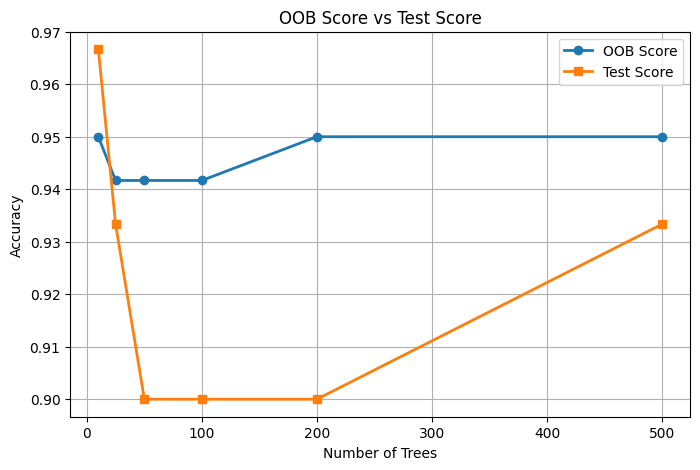

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Number of trees
n_estimators = [10, 25, 50, 100, 200, 500]

oob_scores = []
test_scores = []

print("Trees\tOOB Score\tTest Score")

for n in n_estimators:

    rf = RandomForestClassifier(
        n_estimators=n,
        oob_score=True,
        random_state=42,
        bootstrap=True
    )

    rf.fit(X_train, y_train)

    # OOB Score
    oob_scores.append(rf.oob_score_)

    # Test Score
    y_pred = rf.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    test_scores.append(test_acc)

    print(f"{n}\t{oob_scores[-1]:.4f}\t\t{test_acc:.4f}")

# Plot
plt.figure(figsize=(8,5))

plt.plot(n_estimators, oob_scores,
         marker='o',
         linewidth=2,
         label='OOB Score')

plt.plot(n_estimators, test_scores,
         marker='s',
         linewidth=2,
         label='Test Score')

plt.xlabel("Number of Trees")
plt.ylabel("Accuracy")
plt.title("OOB Score vs Test Score")
plt.legend()
plt.grid(True)

plt.show()

### ⭐ Exercise 3 — "Feature Importance Story" 📖
On the Breast Cancer dataset, get feature importances from a Random Forest. Run the model
**10 times** with different `random_state` values. For the top-5 features, plot their
importance across all 10 runs (10 bar groups side by side). Are the rankings stable?
Now do the same with a single Decision Tree — compare the stability.


Answer:

      Observation:
        - Random Forest shows relatively stable feature importance across 10  
          runs.
        - Decision Tree shows significant variations in feature importance
          across different random states.
        - Random Forest distributes importance more consistently among the
          selected features.
        - Decision Tree often assigns high importance to one feature while
          assigning very low importance to others.
      
      Conclusion:

          Random Forest provides more stable feature importance than a single Decision Tree in this experiment. This is because Random Forest combines multiple decision trees, reducing the impact of variations in individual trees. A single Decision Tree is more sensitive to changes in training data, resulting in greater variations in feature importance.

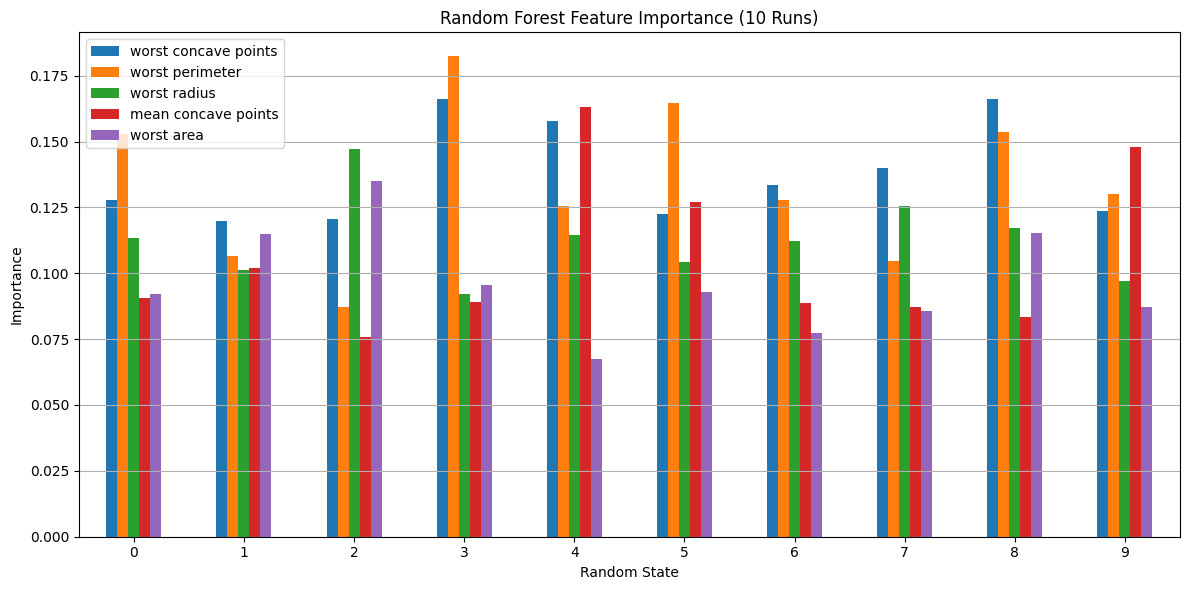

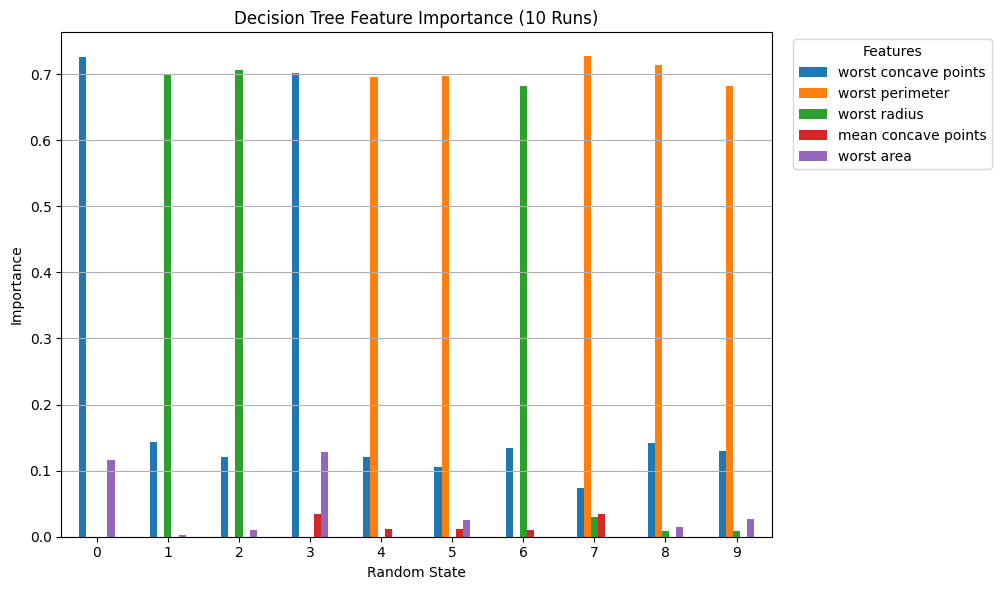

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# -------------------------------
# RANDOM FOREST
# -------------------------------

rf_importances = []

for rs in range(10):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=rs,
        stratify=y
    )

    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=rs
    )

    rf.fit(X_train, y_train)

    rf_importances.append(rf.feature_importances_)

rf_importances = pd.DataFrame(
    rf_importances,
    columns=X.columns
)

# Average importance across 10 runs
rf_mean = rf_importances.mean()

# Top 5 features
top5 = rf_mean.sort_values(ascending=False).head(5).index

# Plot Random Forest Feature Importance
ax = rf_importances[top5].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Random Forest Feature Importance (10 Runs)")
plt.xlabel("Random State")
plt.ylabel("Importance")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# -------------------------------
# DECISION TREE
# -------------------------------

dt_importances = []

for rs in range(10):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=rs,
        stratify=y
    )

    dt = DecisionTreeClassifier(
        random_state=rs
    )

    dt.fit(X_train, y_train)

    dt_importances.append(dt.feature_importances_)

dt_importances = pd.DataFrame(
    dt_importances,
    columns=X.columns
)

# Plot Decision Tree Feature Importance
ax = dt_importances[top5].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Decision Tree Feature Importance (10 Runs)")
plt.xlabel("Random State")
plt.ylabel("Importance")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
ax.legend(
    title="Features",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

### ⭐⭐ Exercise 4 — "Boosting vs Bagging on Noisy Data" 🔬
Generate datasets with noise levels `[0.1, 0.2, 0.3, 0.4, 0.5]` using `make_moons(noise=...)`.
For each noise level, compare Random Forest vs Gradient Boosting (both 100 estimators) using
5-fold CV accuracy. Plot a "noise level vs accuracy" line chart with both models. Which handles
noise better? What does this tell you about when to prefer one over the other?

Answer:
        Observation:
          - As the noise level increases, the accuracy of both models decreases.
          - At noise level 0.1, both models achieve the same accuracy of 99.60%.
          - Gradient Boosting performs slightly better than Random Forest at  
            noise levels 0.2, 0.3, 0.4, and 0.5.
          - At noise level 0.5, Gradient Boosting achieves 81.30% accuracy,
            while Random Forest achieves 79.50%.
          - Both models experience performance degradation as the noise level
            increases.

        Conclusion:

            In this experiment, Gradient Boosting performs slightly better than Random Forest on the generated noisy datasets. However, the performance difference is small.

            Random Forest uses bagging, which combines multiple independent trees to reduce variance. Gradient Boosting builds trees sequentially, with each new tree correcting previous errors.

            This experiment shows that Gradient Boosting performs slightly better on this particular dataset, but it does not mean that Gradient Boosting is always better than Random Forest. Model performance depends on the dataset, noise level, and hyperparameters.

Noise Level | Random Forest | Gradient Boosting
--------------------------------------------------
       0.1 | 0.9960        | 0.9960
       0.2 | 0.9690        | 0.9700
       0.3 | 0.9030        | 0.9130
       0.4 | 0.8400        | 0.8500
       0.5 | 0.7950        | 0.8130


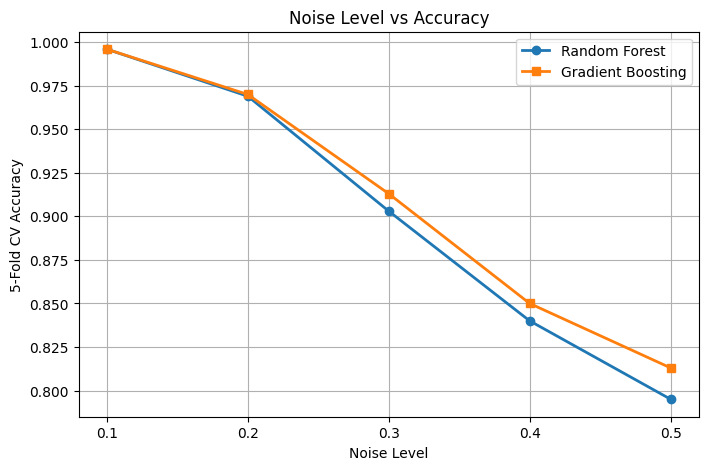

In [15]:
# Exercise 4 - Boosting vs Bagging on Noisy Data

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

# Different noise levels
noise_levels = [0.1, 0.2, 0.3, 0.4, 0.5]

rf_scores = []
gb_scores = []

for noise in noise_levels:

    # Generate dataset
    X, y = make_moons(
        n_samples=1000,
        noise=noise,
        random_state=42
    )

    # Models
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    gb = GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )

    # 5-Fold Cross Validation
    rf_cv = cross_val_score(
        rf,
        X,
        y,
        cv=5,
        scoring="accuracy"
    ).mean()

    gb_cv = cross_val_score(
        gb,
        X,
        y,
        cv=5,
        scoring="accuracy"
    ).mean()

    rf_scores.append(rf_cv)
    gb_scores.append(gb_cv)

# Print Results
print("Noise Level | Random Forest | Gradient Boosting")
print("-" * 50)

for n, rf, gb in zip(noise_levels, rf_scores, gb_scores):
    print(f"{n:10.1f} | {rf:.4f}        | {gb:.4f}")

# Plot
plt.figure(figsize=(8,5))

plt.plot(
    noise_levels,
    rf_scores,
    marker="o",
    linewidth=2,
    label="Random Forest"
)

plt.plot(
    noise_levels,
    gb_scores,
    marker="s",
    linewidth=2,
    label="Gradient Boosting"
)

plt.title("Noise Level vs Accuracy")
plt.xlabel("Noise Level")
plt.ylabel("5-Fold CV Accuracy")
plt.xticks(noise_levels)
plt.grid(True)
plt.legend()

plt.show()

### ⭐⭐ Exercise 5 — "Learning Rate Lab" 🎛️
On the Breast Cancer dataset, train Gradient Boosting with `learning_rate = [0.5, 0.2, 0.1,
0.05, 0.01]` and `n_estimators = 200` fixed. Plot train accuracy vs test accuracy for each
learning rate. Then try `n_estimators=1000` with `learning_rate=0.01` — does more trees +
smaller steps improve things? What's the practical trade-off?

Answer:

      Observation:
        - Learning rates from 0.5 to 0.05 achieve the same test accuracy of 95.
          61%.
        - A learning rate of 0.01 with 200 estimators achieves 92.98% test
          accuracy.
        - Increasing the number of estimators from 200 to 1000 at a learning
          rate of 0.01 improves test accuracy from 92.98% to 95.61%.
        - The training accuracy reaches 100% with 1000 estimators and a
          learning rate of 0.01.

      Conclusion:

          The experiment shows that learning rate and the number of estimators affect Gradient Boosting performance. A smaller learning rate may require more estimators to achieve better performance. Increasing the number of estimators from 200 to 1000 at a learning rate of 0.01 improves test accuracy from 92.98% to 95.61%.

          However, using more estimators increases training time and computational cost. Therefore, we should balance model accuracy and training efficiency when selecting the learning rate and number of estimators.

Learning Rate | Train Accuracy | Test Accuracy
--------------------------------------------------
         0.50 | 1.0000         | 0.9561
         0.20 | 1.0000         | 0.9561
         0.10 | 1.0000         | 0.9561
         0.05 | 1.0000         | 0.9561
         0.01 | 0.9934         | 0.9298


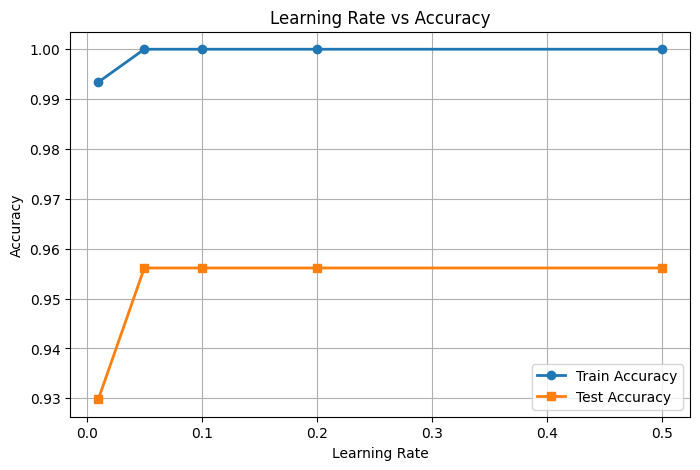


Extra Experiment
----------------
learning_rate = 0.01
n_estimators = 1000
Train Accuracy : 1.0
Test Accuracy  : 0.9561


In [16]:
# Exercise 5 - Learning Rate Lab

import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Learning rates
learning_rates = [0.5, 0.2, 0.1, 0.05, 0.01]

train_acc = []
test_acc = []

# Train models with different learning rates
for lr in learning_rates:

    model = GradientBoostingClassifier(
        learning_rate=lr,
        n_estimators=200,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Accuracy
    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    train_acc.append(train_accuracy)
    test_acc.append(test_accuracy)

# Print Results
print("Learning Rate | Train Accuracy | Test Accuracy")
print("-" * 50)

for lr, tr, te in zip(learning_rates, train_acc, test_acc):
    print(f"{lr:13.2f} | {tr:.4f}         | {te:.4f}")

# Plot
plt.figure(figsize=(8,5))

plt.plot(
    learning_rates,
    train_acc,
    marker="o",
    linewidth=2,
    label="Train Accuracy"
)

plt.plot(
    learning_rates,
    test_acc,
    marker="s",
    linewidth=2,
    label="Test Accuracy"
)

plt.title("Learning Rate vs Accuracy")
plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.show()

# ---------------------------------------------------------
# Extra Experiment
# learning_rate = 0.01
# n_estimators = 1000
# ---------------------------------------------------------

model = GradientBoostingClassifier(
    learning_rate=0.01,
    n_estimators=1000,
    random_state=42
)

model.fit(X_train, y_train)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("\nExtra Experiment")
print("----------------")
print("learning_rate = 0.01")
print("n_estimators = 1000")
print("Train Accuracy :", round(train_accuracy, 4))
print("Test Accuracy  :", round(test_accuracy, 4))

### ⭐⭐ Exercise 6 — "Build a Stacking Ensemble for Iris" 🌸
Use the Iris dataset (3 classes). Build a stacker with:
- Base models: Logistic Regression, Decision Tree (depth=5), Random Forest (100 trees)
- Meta-learner: Logistic Regression
Evaluate using 5-fold CV. Compare against each base model individually. Does the stacker
beat all base models? If not — why might stacking not always win?


Answer:
        Q1. Does the stacking model beat all base models?

        Answer:

        No. The stacking model does not outperform all base models.

        - Logistic Regression achieves the highest accuracy of 97.33%.
        - Random Forest achieves 96.67% accuracy.
        - Stacking achieves 96.00% accuracy.
        - Decision Tree achieves 95.33% accuracy.

          Therefore, Stacking performs better than Decision Tree but worse than Logistic Regression and Random Forest.

        Q2. Why might stacking not always win?

        Answer:

          - The Iris dataset is small and relatively simple.
          - Base models already achieve high accuracy.
          - Logistic Regression alone performs very well on this dataset.
          - If base models make similar predictions, the meta-learner may not
            gain much additional information.
          - Stacking adds another learning step and increases model complexity.

        Therefore, stacking does not always outperform the best individual model, especially on simple datasets like Iris.

In [17]:
# Exercise 6 - Build a Stacking Ensemble for Iris

from sklearn.datasets import load_iris
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
import pandas as pd

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Base models
lr = LogisticRegression(max_iter=1000, random_state=42)

dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Stacking model
stack = StackingClassifier(
    estimators=[
        ('lr', lr),
        ('dt', dt),
        ('rf', rf)
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

# Evaluate using 5-Fold Cross Validation
models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Stacking": stack
}

results = []

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    results.append([
        name,
        scores.mean(),
        scores.std()
    ])

# Display results
df = pd.DataFrame(results, columns=["Model", "Mean Accuracy", "Std Dev"])

print(df)

                 Model  Mean Accuracy   Std Dev
0  Logistic Regression       0.973333  0.024944
1        Decision Tree       0.953333  0.033993
2        Random Forest       0.966667  0.021082
3             Stacking       0.960000  0.024944


### ⭐⭐⭐ Exercise 7 — "Your Own Bagging From Scratch" 🛠️
Without using `BaggingClassifier`, implement bagging manually:
1. Write a function that creates a bootstrap sample (use `rng.choice(..., replace=True)`)
2. Train a Decision Tree on each bootstrap sample
3. For prediction, use majority vote across all trees
Test it on `make_moons(noise=0.3)` with 50 trees.
Compare accuracy against a single tree and sklearn's `BaggingClassifier`.
Do all three give similar results?

Answer:

        Q1. Do all three give similar results?

        Answer:

          Yes. All three models achieve the same accuracy of 91% in this experiment.

          - Single Decision Tree: 91%
          - Manual Bagging: 91%
          - Scikit-learn Bagging: 91%

          This shows that all three models perform similarly on this dataset.

        Q2. Why are Manual Bagging and sklearn Bagging similar?

        Answer:

        - Both use bootstrap sampling (sampling with replacement).
        - Both train multiple Decision Trees independently.
        - Both combine predictions using majority voting.
        - Both follow the same basic bagging principle.

        Therefore, Manual Bagging and Scikit-learn Bagging can produce similar results. However, their predictions and accuracy are not guaranteed to be identical in every experiment.

In [18]:
# Exercise 7 - Implement Bagging From Scratch

import numpy as np
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scipy.stats import mode

# -------------------------------
# Create Dataset
# -------------------------------
X, y = make_moons(n_samples=1000, noise=0.3, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# -------------------------------
# Bootstrap Sampling Function
# -------------------------------
def bootstrap_sample(X, y, rng):
    n = len(X)
    indices = rng.choice(n, size=n, replace=True)
    return X[indices], y[indices]

# -------------------------------
# Manual Bagging
# -------------------------------
rng = np.random.default_rng(42)

n_trees = 50
trees = []

for _ in range(n_trees):

    X_boot, y_boot = bootstrap_sample(X_train, y_train, rng)

    tree = DecisionTreeClassifier(random_state=42)
    tree.fit(X_boot, y_boot)

    trees.append(tree)

# -------------------------------
# Majority Voting
# -------------------------------
predictions = np.array([tree.predict(X_test) for tree in trees])

final_prediction = mode(predictions, axis=0).mode.flatten()

manual_accuracy = accuracy_score(y_test, final_prediction)

# -------------------------------
# Single Decision Tree
# -------------------------------
single_tree = DecisionTreeClassifier(random_state=42)
single_tree.fit(X_train, y_train)

single_accuracy = accuracy_score(
    y_test,
    single_tree.predict(X_test)
)

# -------------------------------
# Sklearn Bagging
# -------------------------------
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=50,
    random_state=42
)

bagging.fit(X_train, y_train)

bagging_accuracy = accuracy_score(
    y_test,
    bagging.predict(X_test)
)

# -------------------------------
# Results
# -------------------------------
print("Single Decision Tree Accuracy :", round(single_accuracy,4))
print("Manual Bagging Accuracy       :", round(manual_accuracy,4))
print("Sklearn Bagging Accuracy      :", round(bagging_accuracy,4))

Single Decision Tree Accuracy : 0.91
Manual Bagging Accuracy       : 0.91
Sklearn Bagging Accuracy      : 0.91
